<a href="https://colab.research.google.com/github/binary-cpu/chokepoint-tracker/blob/main/03_sql_layer.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Chokepoint Traffic: Baseline and Ship-Type Analysis in SQL

**Data snapshot:** through 2026-10-11, accessed 2026-10-14.

**Source**: UN Global Platform; IMF PortWatch

## A. Retrieve Data

rows: 79548 | chokepoints: 28 | span: 2019-01-01 to 2026-10-11
duplicate (portid, date) rows: 0
chokepoints with missing days: 0
columns: ['date', 'year', 'month', 'day', 'portid', 'portname', 'n_container', 'n_dry_bulk', 'n_general_cargo', 'n_roro', 'n_tanker', 'n_cargo', 'n_total', 'capacity_container', 'capacity_dry_bulk', 'capacity_general_cargo', 'capacity_roro', 'capacity_tanker', 'capacity_cargo', 'capacity', 'ObjectId']
matched names: ['Bab el-Mandeb Strait', 'Cape of Good Hope', 'Strait of Hormuz', 'Suez Canal']


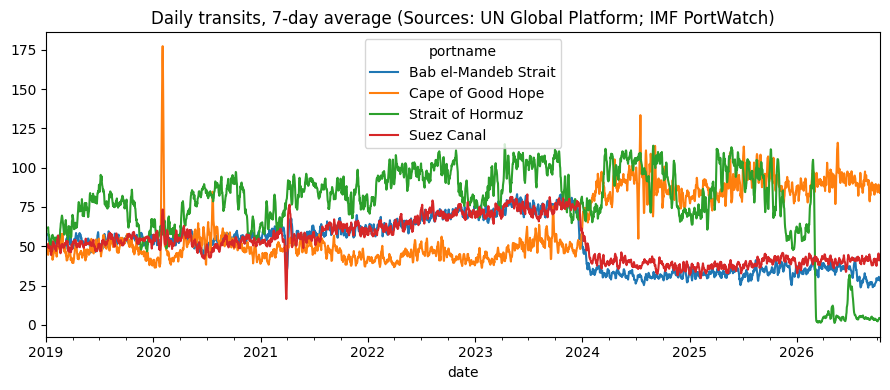

In [ ]:
%pip -q install requests pandas matplotlib
import requests, pandas as pd
import matplotlib.pyplot as plt

BASE = "https://services9.arcgis.com/weJ1QsnbMYJlCHdG/arcgis/rest/services/Daily_Chokepoints_Data/FeatureServer"
CHOKE_DB = "https://services9.arcgis.com/weJ1QsnbMYJlCHdG/arcgis/rest/services/PortWatch_chokepoints_database/FeatureServer"

def layer_url(base):
    info = requests.get(base, params={"f": "json"}, timeout=60).json()
    # Safely get layer ID; if 'layers' is empty or missing, assume the first layer is 0 or base already contains it
    layers = info.get('layers', [])
    if layers:
        layer_id = layers[0]['id']
        return f"{base}/{layer_id}/query"
    elif base.endswith(tuple(str(i) for i in range(10))):
        return f"{base}/query"
    else:
        return f"{base}/0/query"

def fetch_all(base, order=None, page=1000):
    url, rows, offset = layer_url(base), [], 0
    while True:
        params = {"where": "1=1", "outFields": "*", "returnGeometry": "false",
                  "resultOffset": offset, "resultRecordCount": page, "f": "json"}
        if order:
            params["orderByFields"] = order
        r = requests.get(url, params=params, timeout=120).json()
        if "error" in r:
            raise RuntimeError(r["error"])
        feats = r.get("features", [])
        rows += [f["attributes"] for f in feats]
        if not feats or not r.get("exceededTransferLimit"):
            break
        offset += len(feats)
    return pd.DataFrame(rows)

daily = fetch_all(BASE, order="date,portid")
chokes = fetch_all(CHOKE_DB, order="portid")
if pd.api.types.is_numeric_dtype(daily["date"]):
    daily["date"] = pd.to_datetime(daily["date"], unit="ms")
else:
    daily["date"] = pd.to_datetime(daily["date"])

print("rows:", len(daily), "| chokepoints:", daily.portid.nunique(),
      "| span:", daily.date.min().date(), "to", daily.date.max().date())
print("duplicate (portid, date) rows:", int(daily.duplicated(["portid", "date"]).sum()))
span_days = (daily.date.max() - daily.date.min()).days + 1
print("chokepoints with missing days:", int((daily.groupby("portid").date.nunique() < span_days).sum()))
print("columns:", list(daily.columns))

pick = daily[daily.portname.str.contains("Suez|Bab|Hormuz|Cape of Good Hope", case=False, na=False)]
print("matched names:", sorted(pick.portname.unique()))
piv = pick.pivot(index="date", columns="portname", values="n_total").rolling(7).mean()
piv.plot(figsize=(9, 4), title="Daily transits, 7-day average (Sources: UN Global Platform; IMF PortWatch)")
plt.tight_layout(); plt.show()


## B. Load Data into DuckDB

In [ ]:
%pip -q install duckdb
import duckdb
con = duckdb.connect()
con.register("daily", daily)
con.sql("SELECT COUNT(*) AS rows, COUNT(DISTINCT portname) AS chokepoints, MIN(date) AS first_day, MAX(date) AS last_day FROM daily").df()

,rows,chokepoints,first_day,last_day
0,79548,28,2019-01-01,2026-10-11


## C. Query 1: Compare Baseline and Recent Traffic

In [ ]:
Q1 = """
WITH windows AS (
  SELECT * FROM (VALUES
    ('Suez Canal',           DATE '2023-01-01', DATE '2023-10-31'),
    ('Bab el-Mandeb Strait', DATE '2023-01-01', DATE '2023-10-31'),
    ('Cape of Good Hope',    DATE '2023-01-01', DATE '2023-10-31'),
    ('Strait of Hormuz',     DATE '2025-01-01', DATE '2026-01-31')
  ) AS t(portname, base_start, base_end)
),
latest AS (SELECT MAX(date) AS d FROM daily)
SELECT w.portname,
       ROUND(AVG(CASE WHEN d.date BETWEEN w.base_start AND w.base_end THEN d.n_total END), 1) AS baseline_avg_per_day,
       ROUND(AVG(CASE WHEN d.date >= (SELECT d FROM latest) - INTERVAL 27 DAY THEN d.n_total END), 1) AS last_28d_avg_per_day,
       ROUND(100 * (AVG(CASE WHEN d.date >= (SELECT d FROM latest) - INTERVAL 27 DAY THEN d.n_total END)
                  / AVG(CASE WHEN d.date BETWEEN w.base_start AND w.base_end THEN d.n_total END) - 1), 1) AS pct_change
FROM windows w JOIN daily d ON d.portname = w.portname
GROUP BY w.portname ORDER BY w.portname
"""
sql_table = con.sql(Q1).df()
sql_table

,portname,baseline_avg_per_day,last_28d_avg_per_day,pct_change
0,Bab el-Mandeb Strait,74.6,27.4,-63.2
1,Cape of Good Hope,48.9,87.1,78.3
2,Strait of Hormuz,83.4,3.3,-96.1
3,Suez Canal,73.6,41.7,-43.4


**Headline table (data through 2026-10-11).** Against my chosen baselines, the last 28 days average: Suez 41.7 transits a day (-43.4%), Bab el-Mandeb 27.4 (-63.2%), Cape of Good Hope 87.1 (+78.3%), Hormuz 3.3 (-96.1%). These differ slightly from notebook 02 because the data was refreshed (it ended 2026-10-04 there).

Baseline choice matters, especially for Suez; see the sensitivity ranges in notebook 02. Hormuz figures are AIS-observed in PortWatch and sit far below another source's counts (see the source reconciliation in notebook 02).

## D. Verify the SQL Against pandas

In [ ]:
latest = daily.date.max(); rs = latest - pd.Timedelta(days=27)
BASE = {"Suez Canal": ("2023-01-01", "2023-10-31"), "Bab el-Mandeb Strait": ("2023-01-01", "2023-10-31"),
        "Cape of Good Hope": ("2023-01-01", "2023-10-31"), "Strait of Hormuz": ("2025-01-01", "2026-01-31")}
check = {}
for n, (a, b) in BASE.items():
    s = daily[daily.portname == n].set_index("date").n_total
    check[n] = round(100 * (s[rs:latest].mean() / s[a:b].mean() - 1), 1)
sql_pct = dict(zip(sql_table.portname, sql_table['pct_change']))
print({n: (sql_pct[n], check[n]) for n in BASE})
print("SQL and pandas agree:", all(abs(sql_pct[n] - check[n]) < 0.06 for n in BASE))

{'Suez Canal': (-43.4, np.float64(-43.4)), 'Bab el-Mandeb Strait': (-63.2, np.float64(-63.2)), 'Cape of Good Hope': (78.3, np.float64(78.3)), 'Strait of Hormuz': (-96.1, np.float64(-96.1))}
SQL and pandas agree: True


The SQL query and the pandas calculation agree for all four chokepoints, so the saved SQL reproduces the notebook-02 logic.

## E. Query 2: Change by Ship Type

In [ ]:
Q2 = """
WITH windows AS (
  SELECT * FROM (VALUES
    ('Suez Canal',           DATE '2023-01-01', DATE '2023-10-31'),
    ('Bab el-Mandeb Strait', DATE '2023-01-01', DATE '2023-10-31'),
    ('Cape of Good Hope',    DATE '2023-01-01', DATE '2023-10-31'),
    ('Strait of Hormuz',     DATE '2025-01-01', DATE '2026-01-31')
  ) AS t(portname, base_start, base_end)
),
latest AS (SELECT MAX(date) AS d FROM daily),
long AS (
  UNPIVOT daily ON n_container, n_dry_bulk, n_general_cargo, n_roro, n_tanker
  INTO NAME ship_type VALUE transits
)
SELECT w.portname, REPLACE(l.ship_type, 'n_', '') AS ship_type,
       ROUND(AVG(CASE WHEN l.date BETWEEN w.base_start AND w.base_end THEN l.transits END), 1) AS baseline_avg,
       ROUND(AVG(CASE WHEN l.date >= (SELECT d FROM latest) - INTERVAL 27 DAY THEN l.transits END), 1) AS last_28d_avg,
       ROUND(100 * (AVG(CASE WHEN l.date >= (SELECT d FROM latest) - INTERVAL 27 DAY THEN l.transits END)
             / NULLIF(AVG(CASE WHEN l.date BETWEEN w.base_start AND w.base_end THEN l.transits END), 0) - 1), 1) AS pct_change
FROM windows w JOIN long l ON l.portname = w.portname
GROUP BY w.portname, l.ship_type ORDER BY w.portname, l.ship_type
"""
con.sql(Q2).df()

,portname,ship_type,baseline_avg,last_28d_avg,pct_change
0,Bab el-Mandeb Strait,container,19.3,5.4,-72.2
1,Bab el-Mandeb Strait,dry_bulk,19.6,8.5,-56.8
2,Bab el-Mandeb Strait,general_cargo,5.7,3.7,-35.2
3,Bab el-Mandeb Strait,roro,3.8,1.5,-60.7
4,Bab el-Mandeb Strait,tanker,26.2,8.4,-67.9
5,Cape of Good Hope,container,5.9,15.3,159.3
6,Cape of Good Hope,dry_bulk,30.7,44.9,45.9
7,Cape of Good Hope,general_cargo,2.3,4.9,113.7
8,Cape of Good Hope,roro,0.9,4.0,361.2
9,Cape of Good Hope,tanker,9.1,18.0,98.9


**Reading the ship-type table (data through 2026-10-11).** Hormuz fell across every ship type: tankers 46.8 to 0.8 a day (-98.2%) and containers 16.1 to 0.3 (-98.0%); tankers were over half of baseline traffic. At Bab el-Mandeb, containers fell most (-72.2%), then tankers (-67.9%) and dry bulk (-56.8%). Suez fell less for containers (-38.8%) and tankers (-36.9%) than Bab el-Mandeb did, while dry bulk fell about as much (-53.2%); I have not explained this difference. At the Cape of Good Hope every type rose, containers most among the large groups (+159.3%). Percent changes from tiny baselines are unstable (ro-ro at the Cape: 0.9 to 4.0 a day, +361.2%), so absolute changes are shown next. All counts are AIS-observed transits in PortWatch.

## F. Compare Absolute Change by Ship Type

In [ ]:
q2 = con.sql(Q2).df()
q2["abs_change"] = (q2.last_28d_avg - q2.baseline_avg).round(1)
q2.sort_values(["portname", "abs_change"])[["portname", "ship_type", "baseline_avg", "last_28d_avg", "abs_change", "pct_change"]]

,portname,ship_type,baseline_avg,last_28d_avg,abs_change,pct_change
4,Bab el-Mandeb Strait,tanker,26.2,8.4,-17.8,-67.9
0,Bab el-Mandeb Strait,container,19.3,5.4,-13.9,-72.2
1,Bab el-Mandeb Strait,dry_bulk,19.6,8.5,-11.1,-56.8
3,Bab el-Mandeb Strait,roro,3.8,1.5,-2.3,-60.7
2,Bab el-Mandeb Strait,general_cargo,5.7,3.7,-2.0,-35.2
7,Cape of Good Hope,general_cargo,2.3,4.9,2.6,113.7
8,Cape of Good Hope,roro,0.9,4.0,3.1,361.2
9,Cape of Good Hope,tanker,9.1,18.0,8.9,98.9
5,Cape of Good Hope,container,5.9,15.3,9.4,159.3
6,Cape of Good Hope,dry_bulk,30.7,44.9,14.2,45.9


**Reading absolute changes (data through 2026-10-11).** Counted ship type by ship type, the Cape of Good Hope's gain is close in size to Suez's loss: containers +9.4 vs -7.6 a day, tankers +8.9 vs -9.5, dry bulk +14.2 vs -10.3, general cargo +2.6 vs -2.6, ro-ro +3.1 vs -2.1. In total Suez lost about 32 transits a day and the Cape gained about 38. This is consistent with diversion, but it does not show that the same ships moved: the Cape also carries traffic unrelated to the Red Sea, and I have not tested other explanations. Suez and Bab el-Mandeb overlap, so their losses should not be added. Hormuz's fall (about 80 transits a day, tankers alone about 46) is a separate, larger change that this data does not trace to any destination. All counts are AIS-observed transits in PortWatch.

## G. Check Whether the Source Revised Past Data

In [ ]:
h = daily[daily.portname == "Strait of Hormuz"].set_index("date").n_total
print("Hormuz transits 21-27 Sep 2026 in this snapshot:", int(h["2026-09-21":"2026-09-27"].sum()), "(notebook 02 snapshot gave 22)")

Hormuz transits 21-27 Sep 2026 in this snapshot: 22 (notebook 02 snapshot gave 22)


The count for 21-27 Sep 2026 is 22 in both snapshots (through 2026-10-04 and 2026-10-11), so this week's figure was not revised between them. I checked one week at one chokepoint, so this does not show that the source never revises past data.

## H. Key Findings and Limitations

**Key findings (snapshot through 2026-10-11)**
- The saved SQL query and the pandas calculation agree for all four chokepoints. Last 28 days against baseline: Suez 41.7 transits a day (-43.4%), Bab el-Mandeb 27.4 (-63.2%), Cape of Good Hope 87.1 (+78.3%), Hormuz 3.3 (-96.1%).
- Hormuz fell across every ship type: tankers from 46.8 to 0.8 a day (-98.2%) and containers from 16.1 to 0.3 (-98.0%).
- At Bab el-Mandeb, containers fell most (-72.2%), then tankers (-67.9%) and dry bulk (-56.8%). Suez fell less for containers (-38.8%) and tankers (-36.9%), while dry bulk fell -53.2%.
- Counted ship type by ship type, the Cape's gain is close in size to Suez's loss; in total Suez lost about 32 transits a day and the Cape gained about 38.
- The count for 21-27 Sep 2026 was 22 in both snapshots, so that week was not revised between them.

**Limitations**
- The Cape's gain is consistent with diversion from Suez but does not show that the same ships moved; Suez and Bab el-Mandeb overlap, so their losses should not be added.
- Percent changes from tiny baselines are unstable (ro-ro at the Cape: 0.9 to 4.0 a day), so read them with the change per day.
- The revision check covers one week at one chokepoint only.
- Counts are AIS-observed and baselines are my choices.